# Lab 1: Anomaly Detection Without Labels

**Time:** about 75 minutes

Most of the time, a fraud team doesn't have a neat list of past fraud cases to learn from. What it has is a large
number of payments and a feeling that *some* of them look wrong. Anomaly detection turns that feeling into a method:
it learns what normal payments look like and scores each payment by how far it is from normal.

### What "without labels" means

On Day 2 every training example came with the right answer (fraud or not, approved or not). That's **supervised**
learning: the model learns from examples whose answer is known. The known answer is called the **label**.

Here you work **unsupervised**: the model only sees the payments, never the answers. It can't learn "what fraud looks
like", because nobody tells it. It can only learn "what's typical", and then point at what isn't. That's weaker, but
it has one big advantage: it can flag a kind of fraud nobody has seen before.

In this lab you'll:

1. turn raw payment records into features that describe *behaviour*,
2. score every 2025 payment with an **isolation forest** and an **autoencoder**,
3. check the scores against the cases investigators later confirmed (the labels are only used for checking),
4. look hard at the top of the list, because that's where you learn what "anomalous" really means.

### Words you'll meet in this lab

| Word | Plain meaning |
|---|---|
| **label** | the known right answer for an example, here `confirmed_fraud` (1 or 0) |
| **unsupervised** | learning without labels: finding structure or oddities in the data alone |
| **anomaly / outlier** | a record that is very different from most others |
| **anomaly score** | a number per payment; higher means more unusual |
| **feature** | a column the model uses, designed to describe behaviour (e.g. "paid 1.8 × the entitlement") |
| **isolation forest** | a method that scores how easily a payment can be separated from the rest by random splits |
| **autoencoder** | a neural network that learns to copy normal payments; the ones it copies badly are unusual |
| **reconstruction error** | how different the autoencoder's copy is from the original payment |
| **precision** | of the payments you flag, the share that are really fraud |
| **recall** | of all the fraud, the share you flagged |
| **PR-AUC** | one number summarising precision and recall across all cut-offs; higher is better |
| **ROC-AUC** | the chance a random fraud case scores higher than a random normal one; 0.5 = guessing, 1 = perfect |
| **percentile rank** | a score's position from 0 (lowest) to 1 (highest), so different scores can be compared |
| **ensemble** | combining several methods' scores into one |

## Where this lab fits

**What you've done so far.** On Day 1 you found suspicious records by hand with simple rules (claims after a recorded
death, maternity claims against male records). On Day 2 you learned from audited claims to score risk, and you grouped
members with no labels at all. On Day 3 you built neural networks in PyTorch. Day 4 was about forecasting the Fund's
cash.

**What you'll do now.** You'll look at 34,000 benefit payments from 2025 and rank them by how *unusual* they are, without
using any knowledge of which were fraud. You'll engineer features that describe behaviour, then score the payments
three ways (an isolation forest, an autoencoder and ECOD) and combine the three. Only at the end of each step will you
peek at the confirmed cases, to see how well the scores did.

**Why it matters.** Fraudsters change tactics, and most fraud is never confirmed, so a fraud team rarely has a complete
list of past cases to learn from. A method that flags "this doesn't look like the others" can find a new scheme before
anybody has a name for it.

**What happens next.** Lab 2 uses the few confirmed cases to learn what known fraud looks like, which needs special care
because fraud is so rare. Lab 3 combines both kinds of score with business rules into a queue the investigations team can
actually work through.

### Theory: three kinds of "unusual"

Anomalies come in three kinds, and each needs a different way of looking:

| Kind | Meaning | Example in benefit payments |
|---|---|---|
| **Point anomaly** | one value is extreme on its own | a lump sum of 10 times the entitlement |
| **Contextual anomaly** | normal in general, unusual in its context | a pensioner aged 104 who last proved they were alive three years ago; an approval at 21:00 by an officer who never works evenings |
| **Collective anomaly** | each record looks normal, but the group doesn't | six "members" all paid into one mobile money account, all approved by the same officer |

A detector that only sees each payment's raw amount can only find point anomalies. To find the other two, you have to
build the context and the group into the features: amount *compared with entitlement*, an officer's *usual* hours,
*how many members* share an account. That's why Section 2 (features) matters more than the choice of detector.

## 0. Set up today's environment (run this cell first)

You don't need to create a folder or an environment by hand today. The cell below does it for you:

1. It finds the environment you created on Day 1 (`DAY1/Labs/work/fund-ai/.venv`). If it isn't there, it creates it.
2. It installs today's libraries into it from ``requirements.txt``. The first time takes a few minutes; after that, seconds.
3. If this machine has an NVIDIA GPU (graphics processing unit), it switches PyTorch to its GPU build, so training runs much faster.
4. It connects the environment to Jupyter as **Python (fund-ai)**, and tells you if this notebook isn't using it yet.

It's safe to run again at any time. If it prints instructions to switch the kernel, follow them and run it once more.

You don't need to read the code in this cell. It's housekeeping, not part of today's lesson.

In [1]:
# ---- Setup for Day 5. Safe to run more than once. -------------------------------------------------------------
COURSE_ENV = None        # None = use the Day 1 environment. Or set a folder, e.g. Path.home() / "fund-ai-venv"
REQUIREMENTS = "requirements.txt"
EXTRAS = []

import os, shutil, subprocess, sys
from pathlib import Path

labs = Path.cwd()
root = next((p for p in [labs, *labs.parents] if (p / "DAY1").is_dir()), None)
if root is None:
    raise RuntimeError("Open this notebook from inside the course folder (the one that contains DAY1, DAY2, ...).")
env = Path(COURSE_ENV) if COURSE_ENV else root / "DAY1" / "Labs" / "work" / "fund-ai" / ".venv"
py = env / ("Scripts/python.exe" if os.name == "nt" else "bin/python")


def run(*cmd, quiet=False):
    """Run a command; show its output only if it fails."""
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if r.returncode != 0 and not quiet:
        print(r.stdout[-3000:], r.stderr[-3000:])
        if "path" in (r.stderr + r.stdout).lower() and os.name == "nt":
            print("\nIf the error mentions a path that is too long: Windows 'long paths' are switched off on this machine.\n"
                  "Ask ICT to enable them, or set COURSE_ENV above to a short folder, e.g. Path.home() / 'fund-ai-venv'.")
        raise RuntimeError("A setup step failed. The details are printed above.")
    return r


# 1. The course environment
if py.exists():
    print(f"- course environment found: {env}")
else:
    print(f"- creating the course environment (first time only): {env}")
    run(getattr(sys, "_base_executable", sys.executable), "-m", "venv", env)
    run(py, "-m", "pip", "install", "-q", "--upgrade", "pip")

# 2. Today's libraries
req = labs / REQUIREMENTS
print(f"- installing today's libraries from {REQUIREMENTS} ...")
run(py, "-m", "pip", "install", "-q", "-r", req)

# 3. Use the GPU if this machine has an NVIDIA one
if "torch" in req.read_text() and shutil.which("nvidia-smi"):
    if run(py, "-c", "import torch; print(torch.cuda.is_available())").stdout.strip() != "True":
        version = run(py, "-c", "import torch; print(torch.__version__.split('+')[0])").stdout.strip()
        print(f"- NVIDIA GPU found: switching PyTorch {version} to its GPU build (about 2.5 GB, first time only) ...")
        run(py, "-m", "pip", "uninstall", "-y", "-q", "torch")
        run(py, "-m", "pip", "install", "-q", f"torch=={version}", "--index-url", "https://download.pytorch.org/whl/cu124",
            "--extra-index-url", "https://pypi.org/simple")
    print("- PyTorch will use the GPU")

# 4. Anything else today needs
for extra in EXTRAS:
    kind, name = extra.split(":", 1)
    if kind == "spacy" and run(py, "-c", f"import {name}", quiet=True).returncode != 0:
        print(f"- downloading the spaCy model {name} ...")
        run(py, "-m", "spacy", "download", name)
    if kind == "ollama":
        import json, urllib.request
        try:
            tags = json.load(urllib.request.urlopen("http://localhost:11434/api/tags", timeout=3))["models"]
            have = {m["name"] for m in tags}
            wanted = [m for m in name.split(",") if m]
            missing = [m for m in wanted if m not in have]
            print(f"- Ollama is running with {len(have)} model(s)" + (f"; still to pull: {', '.join(missing)}" if missing else ""))
            for m in missing:
                print(f"    in a terminal: ollama pull {m}")
        except OSError:
            print("- Ollama isn't running. Start the Ollama app (or run `ollama serve` in a terminal) before the LLM parts.")

# 5. Connect the environment to Jupyter
run(py, "-m", "ipykernel", "install", "--user", "--name", "fund-ai", "--display-name", "Python (fund-ai)")

# 6. Is this notebook using it?
if Path(sys.prefix).resolve() == env.resolve():
    print("\nReady. This notebook is running in the course environment. Carry on with the next cell.")
else:
    print("\nAlmost there. This notebook is running a different Python:")
    print(f"    {sys.executable}")
    print("Switch it to the course environment, then run this cell once more:")
    print("    1. Click the kernel name in the top right of the notebook, then 'Select Another Kernel'.")
    print("    2. Choose 'Jupyter Kernel' -> 'Python (fund-ai)'.")
    print("       (Or press Ctrl+Shift+P, run 'Python: Select Interpreter', choose 'Enter interpreter path...'")
    print("        and paste the path below, the same way you did on Day 1.)")
    print(f"    {py}")

- course environment found: /Users/daud.mabena/Documents/DUBAI/Training1910Labs/DAY1/Labs/work/fund-ai/.venv
- installing today's libraries from requirements.txt ...

Ready. This notebook is running in the course environment. Carry on with the next cell.


## Imports

New tools today:

- `IsolationForest` from scikit-learn, the first anomaly detector;
- `torch` and `nn` (PyTorch, from Day 3), for the autoencoder;
- `StandardScaler`, to put all features on the same scale before the neural network sees them;
- `average_precision_score` (PR-AUC) and `roc_auc_score` (ROC-AUC), to check the scores against the labels.

The `LOKY_MAX_CPU_COUNT` line avoids a slow, noisy check of the CPU on Windows 11. The two `set_option` lines let
pandas show wide tables in full.

In [2]:
import os
import warnings

# Skip a slow, noisy CPU-core check on Windows 11, and hide library notices.
os.environ["LOKY_MAX_CPU_COUNT"] = str(os.cpu_count() - 1)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.max_columns", 30)     # show up to 30 columns
pd.set_option("display.width", 170)          # use the full width of the screen

Fix the randomness so you get the same results each run (both NumPy and PyTorch have their own random number
generators), and use the GPU if this machine has one. The autoencoder is small, so the CPU is fine too.

In [3]:
SEED = 42
np.random.seed(SEED)         # NumPy's randomness
torch.manual_seed(SEED)      # PyTorch's randomness

# Use the GPU (graphics card) if there is one; otherwise the CPU.
if torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
print("autoencoder will train on:", device)

autoencoder will train on: cpu


> **Where we are.** The libraries are loaded, the randomness is fixed, and you know whether PyTorch will use a GPU.
> First, a look at the payments themselves.

## 1. The payments

`benefit_payments_2025.csv` has one row per benefit payment made in 2025: who was paid, how much, what they were
entitled to, which account it went to, who approved it and when. `member_no` is read as text (`"string"`), because it's
an identifier, not a number to do arithmetic on (and leading zeros must be kept).

In [4]:
pay = pd.read_csv("benefit_payments_2025.csv", parse_dates=["payment_date"], dtype={"member_no": "string"})
print(pay.shape)      # (rows, columns)
pay.head()

(34387, 19)


,payment_id,member_no,benefit_type,payment_type,payment_date,amount_tzs,entitlement_tzs,payee_account,account_type,account_changed_days_ago,members_sharing_account,payee_age,months_since_life_verification,last_verification_channel,branch,approving_officer,approval_hour,days_claim_to_payment,confirmed_fraud
0,PAY25-007063,647468105,UNEMPLOYMENT,INSTALMENT,2025-01-01,235300.0,235300.0,ACC-766296B4,MOBILE_MONEY,4,8,32.5,NaN,NaN,Temeke,OFF-0447,19,5.0,1
1,PAY25-016775,149357832,MATERNITY,GRANT,2025-01-03,1036000.0,1036000.0,ACC-B6B3C123,MOBILE_MONEY,668,1,23.2,NaN,NaN,Temeke,OFF-0263,12,6.0,0
2,PAY25-019751,517937003,UNEMPLOYMENT,INSTALMENT,2025-01-03,137900.0,137900.0,ACC-23430B05,MOBILE_MONEY,172,1,30.8,NaN,NaN,Ilala,OFF-0194,8,32.0,0
3,PAY25-015414,275978363,UNEMPLOYMENT,INSTALMENT,2025-01-04,388600.0,388600.0,ACC-328F6270,MOBILE_MONEY,397,1,39.7,NaN,NaN,Mbeya,OFF-0447,13,44.0,0
4,PAY25-012235,464298060,UNEMPLOYMENT,INSTALMENT,2025-01-05,511800.0,511800.0,ACC-71284C61,BANK,1033,1,29.1,NaN,NaN,Ubungo,OFF-0591,15,45.0,0


What kinds of payment are there? `value_counts()` counts how many rows have each value. Monthly pensions dominate; the
other types (arrears, lump sums, grants, unemployment instalments) are much rarer. Keep that in mind: it matters a lot
in Section 3.

In [5]:
pay["payment_type"].value_counts()

payment_type
MONTHLY_PENSION    32986
INSTALMENT           772
GRANT                422
LUMP_SUM             147
ARREARS               60
Name: count, dtype: int64

How much confirmed fraud is there? `confirmed_fraud` is 1 for fraud and 0 otherwise, so its sum is the number of fraud
payments and its mean is the share.

In [6]:
n_fraud = pay["confirmed_fraud"].sum()                                              # number of fraud payments
fraud_members = pay.loc[pay["confirmed_fraud"] == 1, "member_no"].nunique()         # how many different members
print(f"confirmed fraud: {n_fraud} payments ({pay['confirmed_fraud'].mean():.2%}), {fraud_members} members")

confirmed fraud: 397 payments (1.15%), 66 members


About 1.2% of payments were confirmed as fraud. The investigators got there by following up tip-offs and audit
samples, which means there are almost certainly fraudulent payments in the other 98.8% that nobody has found yet.
Keep that in mind when you "evaluate" against these labels: an anomaly the labels call normal might simply be fraud
nobody caught.

For the rest of this lab, pretend you **don't** have the `confirmed_fraud` column. It's set aside and only brought
back to check your work.

### Theory: judging a detector against incomplete labels

You'll use `confirmed_fraud` to check each detector, but it's an imperfect answer key:

- **Some fraud is unlabelled.** Investigators only confirmed the cases they looked at. A payment the detector flags
  and the labels call "normal" might be fraud nobody has found yet.
- **The labels reflect where people looked.** If investigators mostly followed tip-offs about shared accounts, the
  labelled cases are mostly shared-account fraud. A detector that finds a different kind will look worse than it is.

So treat the scores against the labels as a rough guide to how well each detector concentrates *known* fraud at the
top, not as an exact measure of how much fraud it finds. And always look at the top-ranked payments yourself, which is
what Section 3 does.

> **Where we are.** You know the payment types (mostly monthly pensions) and the fraud rate (about 1.2% confirmed,
> almost certainly more in reality). The `confirmed_fraud` column is now set aside. Next you'll decide which numbers
> describe each payment.

## 2. Features that describe behaviour

A model only sees numbers, so you have to decide which numbers describe a payment well. This step is called **feature
engineering**, and in fraud work it matters more than the choice of model.

The raw columns aren't quite what a detector needs. A payment of TZS 2 million says little on its own. A payment
that's **1.8 times** the member's entitlement says a lot. An officer approving a payment at 21:00 is unusual, but an
officer who approves *many* payments at 21:00 is more unusual still.

Each feature below comes from a question an experienced investigator would ask. They go into a new table, `X`, one
row per payment.

**Amounts and accounts.** `np.log1p` takes the logarithm of (1 + the value). Amounts range from thousands to many
millions; the log squeezes that range so a few huge payments don't dominate. The `1 +` avoids an error for zero.

In [7]:
X = pd.DataFrame(index=pay.index)      # an empty table with one row per payment

# How big is the payment? (log, because amounts are very skewed)
X["log_amount"] = np.log1p(pay["amount_tzs"])

# Paid more than the member is owed? 1.0 = exactly the entitlement.
X["amount_vs_entitlement"] = pay["amount_tzs"] / pay["entitlement_tzs"]

# Was the bank or mobile-money account changed just before?
X["log_days_since_account_change"] = np.log1p(pay["account_changed_days_ago"])

# Is one account receiving money for many members?
X["members_sharing_account"] = pay["members_sharing_account"]

# How old is the person being paid?
X["payee_age"] = pay["payee_age"]

**Pension checks, approval and speed.** Several of these are **flags**: 1 when something is true, 0 when it isn't.
`.astype(int)` turns True/False into 1/0.

A **life verification** is when a pensioner proves they're still alive (in person or by certificate). A long time since
the last one is a classic warning sign of a "ghost" pensioner: someone still being paid after they died.

In [8]:
# Is it a pension-type payment?
X["is_pension"] = pay["payment_type"].isin(["MONTHLY_PENSION", "ARREARS"]).astype(int)

# Months since the pensioner last proved they're alive (empty for non-pensions, so 0).
X["months_since_verification"] = pay["months_since_life_verification"].fillna(0)

# Approved before 08:00 or from 17:00 onwards?
off_hours = (pay["approval_hour"] < 8) | (pay["approval_hour"] >= 17)      # | means "or"
X["off_hours_approval"] = off_hours.astype(int)

# Paid unusually quickly (less than 10 days after the claim)? Empty means not a claim-based payment.
fast = pay["days_claim_to_payment"] < 10
X["fast_payment"] = fast.astype(int)

# Paid to a mobile-money account?
X["mobile_money"] = (pay["account_type"] == "MOBILE_MONEY").astype(int)

**Context about the officer.** One payment approved at 21:00 might be a busy evening. But if an officer approves a
large share of *all* their payments out of hours, that's a pattern worth knowing about.

`groupby(...).transform("mean")` works out each officer's out-of-hours rate across all their payments, then writes that
rate onto *every* payment the officer approved, so the table keeps one row per payment. Compare it with `.mean()`
alone, which would give one row per officer.

In [9]:
# Context: how often does this payment's approving officer approve out of hours, across ALL their payments?
# transform("mean") gives each payment its officer's overall rate.
X["officer_off_hours_rate"] = X["off_hours_approval"].groupby(pay["approving_officer"]).transform("mean")

X[["off_hours_approval", "officer_off_hours_rate"]].head()

,off_hours_approval,officer_off_hours_rate
0,1,0.087948
1,0,0.058288
2,0,0.049724
3,0,0.087948
4,0,0.032668


**Repeated payments.** Paying the same thing twice is a common error and a common fraud. To find repeats:

1. sort the payments by date;
2. group them by member, benefit and amount, so each group is "the same payment to the same person";
3. `diff()` gives the time since the previous payment in the same group; `.dt.days` turns it into days;
4. `reindex(pay.index)` puts the results back in the original row order, so they line up with `X`.

A gap of 10 days or less means a repeat.

In [10]:
# Repeats: the same amount to the same member for the same benefit, within 10 days.
# Sort by date, then diff() = days since the previous payment in the same (member, benefit, amount) group.
by_date = pay.sort_values("payment_date")
gap = by_date.groupby(["member_no", "benefit_type", "amount_tzs"])["payment_date"].diff().dt.days

# gap is in date order; reindex puts it back in the original row order.
gap = gap.reindex(pay.index)
X["repeat_within_10d"] = (gap <= 10).astype(int)
print("repeats within 10 days:", X["repeat_within_10d"].sum())

repeats within 10 days: 19


**Payment type.** A model can't read the text "LUMP_SUM", so each type becomes its own 1/0 column (this is called
**one-hot encoding**). Monthly pension is left out on purpose: a payment with all four columns at 0 *is* a monthly
pension, so a fifth column would add nothing.

Finally, keep the labels in `y`, separate from the features, for checking only. `describe()` gives a quick summary of
every feature: count, average, spread, minimum and maximum. It's a good way to spot a feature that went wrong.

In [11]:
# One 0/1 column per payment type (monthly pension is the one left out: all four zeros).
X["type_arrears"] = (pay["payment_type"] == "ARREARS").astype(int)
X["type_lump_sum"] = (pay["payment_type"] == "LUMP_SUM").astype(int)
X["type_grant"] = (pay["payment_type"] == "GRANT").astype(int)
X["type_instalment"] = (pay["payment_type"] == "INSTALMENT").astype(int)

# The labels, set aside for checking only.
y = pay["confirmed_fraud"].to_numpy()

print(X.shape)
X.describe().T.round(2)       # .T turns the summary sideways: one row per feature

(34387, 16)


,count,mean,std,min,25%,50%,75%,max
log_amount,34387.0,12.74,0.77,10.01,12.30,12.70,13.13,18.98
amount_vs_entitlement,34387.0,1.00,0.01,1.00,1.00,1.00,1.00,2.14
log_days_since_account_change,34387.0,7.30,1.04,1.61,6.95,7.65,8.03,8.37
members_sharing_account,34387.0,1.46,1.55,1.00,1.00,1.00,1.00,11.00
payee_age,34387.0,66.48,16.85,3.80,61.30,68.60,77.20,92.90
is_pension,34387.0,0.96,0.19,0.00,1.00,1.00,1.00,1.00
months_since_verification,34387.0,5.29,3.55,0.00,2.00,5.00,8.00,11.00
off_hours_approval,34387.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00
fast_payment,34387.0,0.01,0.07,0.00,0.00,0.00,0.00,1.00
mobile_money,34387.0,0.28,0.45,0.00,0.00,0.00,1.00,1.00


Notice `repeat_within_10d`. A monthly pension repeats every month, which is normal, so the rule only fires when the
*same amount* goes to the *same member* for the *same benefit* within ten days.

> **Where we are.** Every payment is now described by 16 behavioural features in the table `X`: amounts compared with
> entitlement, account changes and sharing, pension checks, approval timing, officer habits, repeats and payment type.
> Time for the first detector.

## 3. Isolation forest

An isolation forest builds many random trees, each one splitting the data at random until every payment sits
alone. Normal payments are surrounded by similar ones, so it takes many splits to isolate them. Odd payments are
isolated in a few splits. **The fewer splits needed, the more anomalous the payment.**

It needs no labels and no assumptions about what fraud looks like, which is exactly why it's a common first tool.

### Isolation in one picture

Imagine drawing random lines through a cloud of points until each point sits alone in its own box. A point in the
middle of the cloud needs many lines before it's separated from its neighbours. A point far out on its own is isolated
by the first line or two. The isolation forest repeats this hundreds of times, with random lines each time, and scores
every payment by how few lines it took on average. Few lines means unusual.

The settings:

- `n_estimators=300`: build 300 random trees (more trees, steadier scores);
- `contamination="auto"`: don't assume a particular share of anomalies;
- `n_jobs=-1`: use all the CPU cores.

`score_samples` gives *lower* numbers to more unusual payments, which is easy to get wrong. A minus sign flips it, so
that throughout this lab **higher always means more unusual**.

In [12]:
# 300 random trees. No labels: fit() only gets X.
iso = IsolationForest(n_estimators=300, contamination="auto", random_state=SEED, n_jobs=-1)
iso.fit(X)

# score_samples gives LOWER numbers to more unusual payments. A minus sign flips it: higher = more anomalous.
pay["iso_score"] = -iso.score_samples(X)
pay["iso_score"].describe()

count    34387.000000
mean         0.424182
std          0.064508
min          0.349506
25%          0.379033
50%          0.405024
75%          0.447209
max          0.769333
Name: iso_score, dtype: float64

### Theory: why the top of the list is what counts

An investigations team might be able to open a few hundred cases a quarter, out of 34,000 payments. Whatever the
detector does at rank 20,000 makes no difference to anybody. What matters is how much real fraud sits in the top few
hundred.

That's why the measures here focus on the **top 1%**, and on PR-AUC, which rewards fraud near the top. It's also why a
high ROC-AUC can mislead: with 1.2% fraud, a detector can rank most fraud above most normal payments (a good ROC-AUC)
while the top of the list is still full of normal payments (a poor precision).

A useful comparison is always **random selection**: picking 1% of payments at random would give a precision of about
1.2%, the fraud rate. Any detector worth using does many times better than that.

### How good is it, compared with the labels?

Now bring the labels back, only to check. Investigators can't review 34,000 payments; they'll work from the top of the
list. So the measures that matter are about the top:

- **Precision in the top 1%:** of the 344 most anomalous payments, what share were confirmed fraud? If you sent those
  344 to investigators, how many would turn out to be real cases?
- **Recall in the top 1%:** of all the confirmed fraud, what share is in those 344?
- **PR-AUC** (area under the precision-recall curve): one number for how well fraud is concentrated at the top, across
  every possible cut-off, not just 1%. It's the better guide when positives are rare. A random ordering scores about
  0.012 (the fraud rate), so anything well above that is doing real work.

Work out the top-1% numbers once by hand, so you see exactly what they mean:

In [13]:
# Work it out once by hand: the top 1% of payments by score.
n_top = round(0.01 * len(pay))
top = pay.sort_values("iso_score", ascending=False).head(n_top)      # highest scores first, keep the top 1%

print("payments in the top 1%:", n_top)
print("confirmed fraud among them:", top["confirmed_fraud"].sum())
print("precision in the top 1%:", round(top["confirmed_fraud"].mean(), 3))
print("recall (share of all fraud caught):", round(top["confirmed_fraud"].sum() / pay["confirmed_fraud"].sum(), 3))

payments in the top 1%: 344
confirmed fraud among them: 29
precision in the top 1%: 0.084
recall (share of all fraud caught): 0.073


You'll score several methods the same way, so put it in a function that returns one row of results. It also reports
**ROC-AUC**: the chance that a randomly chosen fraud payment scores higher than a randomly chosen normal one (0.5 is
no better than guessing, 1.0 is perfect). ROC-AUC tends to look high when fraud is rare, which is why PR-AUC and
the top-1% numbers are the ones to watch.

In [14]:
def report(name, scores):
    """PR-AUC, ROC-AUC, and precision and recall in the top 1%, for one set of anomaly scores."""
    ranked = pd.DataFrame({"fraud": y, "score": np.asarray(scores)})
    ranked = ranked.sort_values("score", ascending=False)        # most unusual first
    top = ranked.head(round(0.01 * len(ranked)))                 # the top 1%
    return {
        "method": name,
        "PR-AUC": average_precision_score(y, scores),
        "ROC-AUC": roc_auc_score(y, scores),
        "precision top 1%": top["fraud"].mean(),
        "recall top 1%": top["fraud"].sum() / ranked["fraud"].sum(),
    }


# Keep one row per method in a list, and show it as a table.
results = []
results.append(report("Isolation forest", pay["iso_score"]))
pd.DataFrame(results).set_index("method").round(3)

,PR-AUC,ROC-AUC,precision top 1%,recall top 1%
method,,,,
Isolation forest,0.101,0.893,0.084,0.073


### Now look at what it actually found

A score is only useful if you understand what's behind it. Look at the 15 most anomalous payments, with the columns an
investigator would check first:

In [15]:
cols = ["payment_type", "benefit_type", "amount_tzs", "entitlement_tzs", "members_sharing_account",
        "account_changed_days_ago", "payee_age", "approval_hour", "confirmed_fraud", "iso_score"]
pay.sort_values("iso_score", ascending=False)[cols].head(15)

,payment_type,benefit_type,amount_tzs,entitlement_tzs,members_sharing_account,account_changed_days_ago,payee_age,approval_hour,confirmed_fraud,iso_score
17057,GRANT,MATERNITY,2232000.0,2232000.0,6,13,27.0,18,0,0.769333
11370,GRANT,MATERNITY,1805200.0,1805200.0,8,25,27.6,17,1,0.768812
8501,GRANT,MATERNITY,1395100.0,1395100.0,6,7,28.9,18,1,0.766414
19907,GRANT,MATERNITY,1242300.0,1242300.0,8,44,30.8,19,1,0.765205
31452,INSTALMENT,UNEMPLOYMENT,140400.0,140400.0,8,30,26.9,19,1,0.760516
19922,INSTALMENT,UNEMPLOYMENT,138400.0,138400.0,7,25,25.8,17,0,0.759659
87,INSTALMENT,UNEMPLOYMENT,231400.0,231400.0,8,12,31.4,18,1,0.759119
0,INSTALMENT,UNEMPLOYMENT,235300.0,235300.0,8,4,32.5,19,1,0.759119
28606,INSTALMENT,UNEMPLOYMENT,285300.0,285300.0,7,5,32.6,18,1,0.756385
2865,INSTALMENT,UNEMPLOYMENT,233400.0,233400.0,8,26,37.0,21,1,0.754536


You'll see a mixture. Some of these are real fraud patterns: several members paid into one account, money approved
in the evening, payments far above the entitlement. Many aren't: they're simply grants and unemployment instalments,
which are ordinary payments that happen to be much **rarer** than monthly pensions.

Count what's in the top 1% by payment type, next to how common each type is overall. `normalize=True` gives shares
instead of counts. `fillna(0)` shows 0 for a type with no fraud in the top 1%.

In [16]:
top = pay.sort_values("iso_score", ascending=False).head(n_top)

by_type = pd.DataFrame({
    "in top 1%": top["payment_type"].value_counts(),
    "confirmed fraud": top.groupby("payment_type")["confirmed_fraud"].sum(),
    "share of all payments": pay["payment_type"].value_counts(normalize=True).round(3),
})
by_type.fillna(0)

,in top 1%,confirmed fraud,share of all payments
payment_type,,,
ARREARS,0.0,0.0,0.002
GRANT,201.0,6.0,0.012
INSTALMENT,98.0,18.0,0.022
LUMP_SUM,43.0,5.0,0.004
MONTHLY_PENSION,2.0,0.0,0.959


This is the most important lesson of the lab: **an anomaly detector finds what's rare, and rare isn't the same as
wrong.** Lump sums are rare compared with monthly pensions, so they float to the top whether or not anything is
wrong with them. If you sent this list straight to the investigations team, a lot of their time would go on
perfectly normal lump sums.

Two ways to deal with that, and you'll use both:

1. **Compare like with like.** Score pensions against pensions and one-off payments against one-off payments.
2. **Bring in what the business already knows.** Lab 3 combines scores with rules and context.

**Your turn (1).** Fit a separate isolation forest for monthly pensions only (`payment_type == "MONTHLY_PENSION"`)
and another for everything else. Put the scores back together, scaling each group's scores to its own percentiles
(`rank(pct=True)`), and compute the same report. Does comparing like with like help?

In [17]:
# Your code here

> **Where we are.** The isolation forest concentrates confirmed fraud far above chance, but its top list is crowded with
> rare-but-legitimate payment types. You've seen that "rare" and "wrong" aren't the same thing. The next detector works
> on a completely different idea.

### Theory: learning "normal" by learning to copy

An autoencoder is trained on one task only: **reproduce its input**. That sounds pointless, until you add the
bottleneck. To get 16 numbers through a layer of 3 and back out again, the network has to learn a compact summary of
what payments are usually like: which features tend to go together, and what typical combinations look like.

That summary is learned from the bulk of the data, which is normal payments. So:

- a **normal** payment fits the summary and comes back almost unchanged: small **reconstruction error**;
- an **unusual** payment doesn't fit, and comes back wrong in the features that make it unusual: large error.

Two useful side effects. The error for each feature tells you *why* a payment was flagged, which you'll use in Step 4.
And because the autoencoder learns combinations, it can catch payments where each value looks fine on its own but the
combination is odd, which the isolation forest finds harder.

## 4. An autoencoder

An autoencoder is a neural network trained to copy its input to its output through a narrow middle layer.
Squeezed through that bottleneck, it can only reconstruct well the patterns it has seen many times, which means
normal payments. Unusual payments come out badly reconstructed. **The reconstruction error is the anomaly score.**

```
16 features ─► 8 ─► 3 (bottleneck) ─► 8 ─► 16 features
                  "what's typical"
```

An everyday comparison: if you describe a typical pension payment to a colleague in three words, they can picture
it fairly accurately. Describe a very odd payment in three words, and their picture will be wrong in several places.
The autoencoder's three-number middle layer plays the role of those three words.

### Step 1: scale the features

Neural networks learn badly when features are on very different scales (Day 3): `payee_age` runs into the 80s while
the flags are 0 or 1. `StandardScaler` rescales every feature to an average of 0 and a spread of 1. Then the table is
turned into a PyTorch **tensor** of 32-bit decimals, the format the network expects.

In [18]:
# Scale every feature to mean 0, spread 1, and turn the table into a float32 tensor.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
Xs = torch.tensor(X_scaled, dtype=torch.float32)
print(Xs.shape)      # (payments, features)

torch.Size([34387, 16])


### Step 2: build the network

`nn.Sequential` stacks layers in order, as on Day 3:

- `nn.Linear(a, b)` turns `a` numbers into `b` numbers with learned weights;
- `nn.ReLU()` lets the network learn curved relationships, not just straight lines.

The first half (the **encoder**) squeezes 16 numbers down to 3; the second half (the **decoder**) rebuilds all 16 from
those 3. **Adam** is the optimiser that adjusts the weights, and `lr=1e-3` (0.001) is its step size.

A `DataLoader` serves the payments in **mini-batches** of 256, shuffled each epoch. Notice there's no `y`: the
network's target is its own input.

In [19]:
n_features = Xs.shape[1]

autoencoder = nn.Sequential(
    # encoder: squeeze 16 numbers down to 3
    nn.Linear(n_features, 8),
    nn.ReLU(),
    nn.Linear(8, 3),
    # decoder: rebuild all 16 from those 3
    nn.ReLU(),
    nn.Linear(3, 8),
    nn.ReLU(),
    nn.Linear(8, n_features),
)
autoencoder = autoencoder.to(device)      # move it to the GPU if there is one

optimiser = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)

# Mini-batches of 256 payments. No labels: the input IS the target.
loader = torch.utils.data.DataLoader(Xs, batch_size=256, shuffle=True)

### Step 3: train it

The same training loop as Day 3. For each mini-batch:

1. pass the payments through the network to get the rebuilt version;
2. measure the **loss**: the average squared difference between the input and its rebuild;
3. `zero_grad()` clears the previous step's gradients, `backward()` works out how each weight should change, and
   `step()` changes them.

One pass through all the payments is an **epoch**; you'll do 30. The chart shows the average loss per epoch: it should
fall quickly, then flatten out as the network learns what typical payments look like.

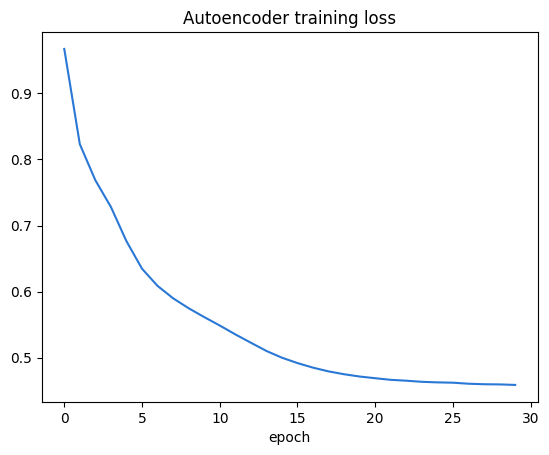

In [20]:
losses = []      # average loss of each epoch, for the chart

for epoch in range(30):
    autoencoder.train()                         # training mode
    total_loss = 0.0
    for xb in loader:
        xb = xb.to(device)
        rebuilt = autoencoder(xb)
        loss = ((rebuilt - xb) ** 2).mean()     # mean squared difference between input and its rebuild

        optimiser.zero_grad()                   # clear the old gradients
        loss.backward()                         # work out how each weight should change
        optimiser.step()                        # change them a little
        total_loss = total_loss + loss.item() * len(xb)
    losses.append(total_loss / len(Xs))         # average over all payments

plt.plot(losses, color="#2a78d6")
plt.title("Autoencoder training loss")
plt.xlabel("epoch")
plt.show()

### Step 4: score every payment

Pass every payment through the trained network once more and measure how badly each one was rebuilt. `eval()` switches
to scoring mode, and `torch.no_grad()` tells PyTorch not to keep track of gradients, since nothing is being trained.
`.cpu()` brings the results back from the GPU.

The squared error has one value per payment per feature. Averaging across the features (`mean(dim=1)`) gives one
score per payment. Then report it next to the isolation forest.

In [21]:
# Rebuild every payment, and measure how badly each one was rebuilt.
autoencoder.eval()
with torch.no_grad():
    recon = autoencoder(Xs.to(device)).cpu()

squared_error = (recon - Xs) ** 2                   # one error per payment per feature
pay["ae_score"] = squared_error.mean(dim=1).numpy()  # average over the features: one score per payment

results.append(report("Autoencoder", pay["ae_score"]))
pd.DataFrame(results).set_index("method").round(3)

,PR-AUC,ROC-AUC,precision top 1%,recall top 1%
method,,,,
Isolation forest,0.101,0.893,0.084,0.073
Autoencoder,0.058,0.828,0.137,0.118


The autoencoder was trained on *all* payments, fraud included. That works because fraud is so rare the network
can't afford to learn it, but it's worth knowing that training on payments you believe are clean usually helps.

Which features does the autoencoder struggle with most for the top-scoring payments? The per-feature error tells
you *why* a payment was flagged, which is something an investigator will ask. `nlargest(200)` picks the 200 payments
with the highest score; averaging their errors per feature shows which features they get wrong most.

In [22]:
# The error per feature, as a table with the feature names.
per_feature = pd.DataFrame(squared_error.numpy(), columns=X.columns, index=pay.index)

# The 200 payments with the highest autoencoder score, and their average error per feature.
top_200 = pay["ae_score"].nlargest(200).index
per_feature.loc[top_200].mean().sort_values(ascending=False).head(8).round(2)

repeat_within_10d                150.419998
type_arrears                     147.009995
amount_vs_entitlement             76.389999
type_lump_sum                     30.469999
fast_payment                      10.410000
type_grant                         4.360000
is_pension                         3.250000
log_days_since_account_change      2.960000
dtype: float32

> **Where we are.** You have two detectors built on very different ideas (random splits, and learning to copy), each
> scored the same way against the confirmed cases. A third, simpler method gives a useful extra point of view.

## 5. A third opinion: PyOD

PyOD (Python Outlier Detection) is a library of more than 40 anomaly detectors that are all used in the same way.
ECOD (Empirical Cumulative distribution-based Outlier Detection) is a good one to know. For each feature on its own, it
asks "how extreme is this value compared with everyone else's?" (for example, "only 0.1% of payments have an account
changed this recently"), then adds those up across features. It needs no settings and is fast.

`decision_scores_` holds the score for each payment; higher means more unusual, as with the others.

In [23]:
from pyod.models.ecod import ECOD

ecod = ECOD()
ecod.fit(X.to_numpy())      # no labels, as before

# decision_scores_: higher = more anomalous.
pay["ecod_score"] = ecod.decision_scores_

results.append(report("ECOD (PyOD)", pay["ecod_score"]))
pd.DataFrame(results).set_index("method").round(3)

,PR-AUC,ROC-AUC,precision top 1%,recall top 1%
method,,,,
Isolation forest,0.101,0.893,0.084,0.073
Autoencoder,0.058,0.828,0.137,0.118
ECOD (PyOD),0.120,0.891,0.108,0.093


> **Where we are.** Three detectors, three sets of scores, all with "higher means more unusual". Each has its own
> strengths and blind spots. Combining them is the next step.

### Theory: why ensembles help

Each detector makes mistakes, but different detectors tend to make **different** mistakes: the isolation forest is
drawn to rare payment types, ECOD to extreme single values, the autoencoder to odd combinations. When you average their
rankings, a payment that only one method likes moves down, and a payment that all three flag moves to the top.

That's why the Spearman correlations in the next cell matter. If two methods rank the payments in almost the same
order (correlation near 1), the second one adds little. Methods that partly disagree add the most to an ensemble.

## 6. Do the methods agree?

When different methods, built on different ideas, flag the same payment, you can be more confident it deserves a
look. Combining methods like this is called an **ensemble**.

There's a snag: the three scores are on completely different scales (the isolation forest gives values around 0.5,
the autoencoder small decimals, ECOD values in the tens), so you can't simply average them. Instead, turn each into a
**percentile rank**: 1.0 for the most unusual payment, 0.5 for the middle one, close to 0 for the most ordinary. Then
average the three percentiles.

In [24]:
score_cols = ["iso_score", "ae_score", "ecod_score"]

# rank(pct=True) turns each score into a percentile (0 to 1), so the three are on the same scale.
percentiles = pay[score_cols].rank(pct=True)

# The ensemble score is the average of the three percentiles.
pay["ensemble_score"] = percentiles.mean(axis=1)

results.append(report("Ensemble (average rank)", pay["ensemble_score"]))
pd.DataFrame(results).set_index("method").round(3)

,PR-AUC,ROC-AUC,precision top 1%,recall top 1%
method,,,,
Isolation forest,0.101,0.893,0.084,0.073
Autoencoder,0.058,0.828,0.137,0.118
ECOD (PyOD),0.120,0.891,0.108,0.093
Ensemble (average rank),0.107,0.889,0.116,0.101


How similar are the three rankings? **Spearman correlation** compares the *order* of two lists: 1 means they rank
payments in exactly the same order, 0 means the orders are unrelated. Methods that disagree more have more to add to
each other in an ensemble.

In [25]:
# How similar are the three rankings? 1 = identical order, 0 = unrelated.
pay[score_cols].corr(method="spearman").round(2)

,iso_score,ae_score,ecod_score
iso_score,1.00,0.77,0.87
ae_score,0.77,1.00,0.74
ecod_score,0.87,0.74,1.00


## 7. Wrap-up

What you have now is a ranking of 34,000 payments by how unusual they are, built without a single label. It
concentrates confirmed fraud towards the top, far better than chance, but it also puts plenty of legitimate
payments up there.

That's what unsupervised detection is good for: **a starting point** that works even for fraud patterns nobody has
seen before. In Lab 2 you'll use the confirmed cases to learn what fraud specifically looks like, and in Lab 3 you'll
combine both with rules into a queue investigators can work.

Save the scores for Lab 3. Only the payment ID and the four scores are needed:

In [26]:
pay[["payment_id", "iso_score", "ae_score", "ecod_score", "ensemble_score"]].to_csv("anomaly_scores.csv", index=False)
print("saved anomaly_scores.csv")

saved anomaly_scores.csv


---

## Looking back, looking ahead

**What you did in this lab.** Without using any labels, you built behavioural features, scored 34,000 payments with an
isolation forest, an autoencoder and ECOD, explained what each found, and combined them into one ensemble ranking.
You checked each step against the confirmed cases, knowing those labels are incomplete. The scores are saved in
`anomaly_scores.csv` for Lab 3.

**The ideas to carry forward.**

- Features that carry context and group behaviour matter more than the choice of detector.
- Unusual isn't the same as fraudulent: rare payment types float to the top for no bad reason.
- Measure where the investigators work: the top of the list.
- Different methods catch different things; combine them.

**What happens next.** In Lab 2 you'll use the confirmed cases to train a model that learns what known fraud looks like,
and you'll see what it takes to learn from an outcome as rare as 1.2%.

## Your turn (more)

2. **Members, not payments.** A ghost pensioner produces twelve suspicious payments a year. Investigators think in
   members, not payments. Aggregate the ensemble score to one row per `member_no` (take the maximum), then compute
   precision in the top 1% of *members*. Is it better or worse than at payment level?
3. **Accounts.** Group payments by `payee_account` and list the accounts receiving money for four or more
   different members. For each, show the members' ages, benefit types and approving officers. Which of them look
   like the guardian of a family of survivors, and which don't?

In [27]:
# Your code here

## Suggested answers

**(1)** Like with like. Two separate forests, one per group. Because each forest scores on its own scale, the scores are
turned into percentiles within each group before being put back together. `~is_monthly` means "not monthly".

In [28]:
is_monthly = pay["payment_type"] == "MONTHLY_PENSION"

# A forest for monthly pensions only.
iso_monthly = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1)
iso_monthly.fit(X[is_monthly])
monthly_scores = pd.Series(-iso_monthly.score_samples(X[is_monthly]), index=X[is_monthly].index)

# A forest for everything else.
iso_other = IsolationForest(n_estimators=300, random_state=SEED, n_jobs=-1)
iso_other.fit(X[~is_monthly])
other_scores = pd.Series(-iso_other.score_samples(X[~is_monthly]), index=X[~is_monthly].index)

# Turn each group's scores into percentiles within that group, then put them back together in the original order.
split_score = pd.concat([monthly_scores.rank(pct=True), other_scores.rank(pct=True)]).sort_index()

comparison = [report("Isolation forest (all together)", pay["iso_score"]),
              report("Isolation forest (split by type)", split_score)]
pd.DataFrame(comparison).set_index("method").round(3)

,PR-AUC,ROC-AUC,precision top 1%,recall top 1%
method,,,,
Isolation forest (all together),0.101,0.893,0.084,0.073
Isolation forest (split by type),0.122,0.915,0.235,0.204


**(2)** Member level. `agg` builds one row per member with two columns: their highest score, and whether *any* of
their payments was fraud (the maximum of 0s and 1s is 1 if there's at least one 1).

In [29]:
# One row per member: their highest payment score, and whether any of their payments was fraud.
by_member = pay.groupby("member_no").agg(
    score=("ensemble_score", "max"),
    fraud=("confirmed_fraud", "max"),
)

n_top_members = round(0.01 * len(by_member))
top_members = by_member.sort_values("score", ascending=False).head(n_top_members)

print("members:", len(by_member), "| top 1% =", n_top_members)
print("precision:", round(top_members["fraud"].mean(), 2))
print("recall:   ", round(top_members["fraud"].sum() / by_member["fraud"].sum(), 2))

members: 3945 | top 1% = 39
precision: 0.54
recall:    0.32


**(3)** Shared accounts. Keep the payments to accounts shared by 4 or more members, then summarise each account:

In [30]:
shared = pay[pay["members_sharing_account"] >= 4]

shared_accounts = shared.groupby("payee_account").agg(
    members=("member_no", "nunique"),                 # how many different members
    benefit_types=("benefit_type", "unique"),         # the list of different benefit types
    min_age=("payee_age", "min"),
    max_age=("payee_age", "max"),
    officers=("approving_officer", "nunique"),        # how many different officers approved them
    fraud=("confirmed_fraud", "max"),
)
shared_accounts.sort_values("members", ascending=False)

,members,benefit_types,min_age,max_age,officers,fraud
payee_account,,,,,,
ACC-2A0816A8,11,"[OLD_AGE_PENSION, FUNERAL_GRANT, SURVIVORS_PEN...",30.0,88.2,12,0
ACC-0AF9DAD8,10,[OLD_AGE_PENSION],75.7,92.6,1,1
ACC-B5DF675E,10,"[OLD_AGE_PENSION, INVALIDITY_PENSION]",41.5,80.3,11,0
ACC-0BB07984,10,[OLD_AGE_PENSION],56.4,84.8,9,0
ACC-780646A1,10,"[OLD_AGE_PENSION, INVALIDITY_PENSION]",30.5,80.6,10,0
ACC-897E340F,9,[OLD_AGE_PENSION],60.3,91.3,9,0
ACC-766296B4,8,"[UNEMPLOYMENT, MATERNITY]",25.4,38.0,1,1
ACC-FEF3CD6A,8,"[OLD_AGE_PENSION, SURVIVORS_PENSION]",13.4,84.8,9,0
ACC-8009F5AC,7,"[OLD_AGE_PENSION, SURVIVORS_PENSION]",4.1,74.6,7,0


Look at the `officers` column. The legitimate shared accounts (joint accounts of elderly couples, a son's mobile
money number used for both parents, rural SACCO (savings and credit co-operative) accounts that collect for several
pensioners) had their payments approved by many different officers over the year, as you'd expect for routine monthly
pensions. The fraudulent ones were approved by **one** officer every time, and several of them are for elderly members
whose accounts changed recently. The data points you at the difference, but it takes a person with the claim files
open to confirm it.